# ¿La simulación COMPASS se relaciona con el MLQ externo?

**Pregunta.** ¿Las decisiones tomadas en COMPASS y la telemetría del cursor (tiempos, cambios entre opciones, exploración) correlacionan con el MLQ-5X externo (`puntajes_ext.csv`) o permiten predecirlo?

**Unidad de análisis: la persona (n = 60).** El MLQ externo se mide una sola vez por participante, así que las 1.636 decisiones se agregan a una fila por persona.

Pasos (siguiendo las clases 1 a 3):

1. Definir la variable objetivo (Y) y revisar su estructura.
2. Construir las variables predictoras (X): decisiones y telemetría ajustada por nodo.
3. Diagnóstico de datos.
4. Correlaciones de Spearman con corrección por comparaciones múltiples.
5. Modelos predictivos con validación cruzada, comparados contra un benchmark.
6. Prueba de permutación: ¿el desempeño supera al azar?
7. Importancia de variables (solo si algún modelo supera el benchmark).

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from statsmodels.stats.multitest import multipletests

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=UserWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

SEED = 42
DATA = Path("../data") if Path("../data").exists() else Path("data")

DIMS = ["iia", "iic", "mi", "ei", "ci", "rc", "dpe_a", "dpe_p", "lf"]
NOMBRES = {
    "iia": "Influencia idealizada (atributos)",
    "iic": "Influencia idealizada (conductas)",
    "mi": "Motivación inspiradora",
    "ei": "Estimulación intelectual",
    "ci": "Consideración individualizada",
    "rc": "Recompensa contingente",
    "dpe_a": "Dirección por excepción activa",
    "dpe_p": "Dirección por excepción pasiva",
    "lf": "Laissez-faire",
}

## 0. Carga de datos

In [2]:
ext = pd.read_csv(DATA / "puntajes_ext.csv")
compass = pd.read_csv(DATA / "puntajes_compass.csv")
decisiones = pd.read_csv(DATA / "explicit_decisions.csv",
                         usecols=["session_id", "user_id", "node_id", "option_id", "decision_order"])
opciones = pd.read_csv(DATA / "option_process_stats.csv")
logs = pd.read_csv(DATA / "process_logs.csv",
                   usecols=["session_id", "user_id", "node_id", "node_total_duration_ms",
                            "hover_switch_count", "selected_option_was_most_hovered",
                            "first_hover_option_id", "last_hover_option_id", "final_choice"])

print("MLQ externo:", ext.shape, "| puntajes COMPASS:", compass.shape)
print("Decisiones:", decisiones.shape, "| stats por opción:", opciones.shape, "| eventos:", logs.shape)
assert set(ext.user_id) == set(compass.user_id) == set(decisiones.user_id)

MLQ externo: (60, 10) | puntajes COMPASS: (60, 11)
Decisiones: (1636, 5) | stats por opción: (4416, 7) | eventos: (19153, 9)


## 1. Variable objetivo: MLQ externo

Las 9 dimensiones del MLQ externo están muy correlacionadas entre sí. Según la clase 3, la redundancia vuelve inestables los coeficientes y obliga a corregir por más pruebas. Por eso, además de las 9 dimensiones, se construyen **3 puntajes compuestos**, que son los objetivos principales:

| Compuesto | Dimensiones |
|---|---|
| `transformacional` | iia, iic, mi, ei, ci |
| `transaccional` | rc, dpe_a |
| `pasivo` | dpe_p, lf |

El alfa de Cronbach indica si las dimensiones de cada compuesto miden algo en común (≥ 0,7 se considera aceptable). Si un compuesto sale bajo, conviene interpretarlo con cautela y mirar sus dimensiones por separado.

transformacional  alfa = 0.76
transaccional     alfa = 0.30
pasivo            alfa = 0.77


,mean,std,min,max
iia,13.050,2.166,5.0,16.0
iic,12.750,1.743,8.0,16.0
mi,12.650,2.489,6.0,16.0
ei,13.317,1.836,9.0,16.0
ci,13.283,1.708,9.0,16.0
rc,13.417,1.690,10.0,16.0
dpe_a,11.483,2.111,7.0,16.0
dpe_p,6.667,1.791,4.0,11.0
lf,6.317,2.079,4.0,12.0
transformacional,13.010,1.437,9.4,15.6


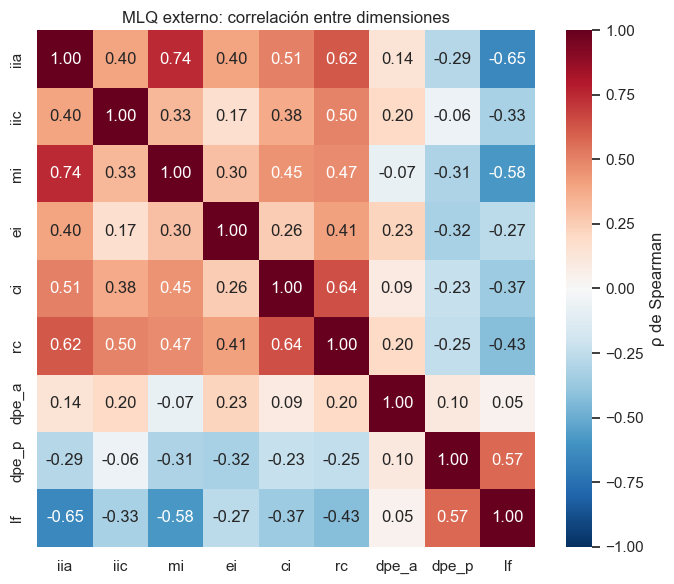

In [3]:
Y = ext.set_index("user_id")[DIMS].copy()
COMPUESTOS = {
    "transformacional": ["iia", "iic", "mi", "ei", "ci"],
    "transaccional": ["rc", "dpe_a"],
    "pasivo": ["dpe_p", "lf"],
}
for nombre, cols in COMPUESTOS.items():
    Y[nombre] = Y[cols].mean(axis=1)

# Consistencia interna de cada compuesto (alfa de Cronbach sobre las subescalas)
def alfa_cronbach(df):
    k = df.shape[1]
    return k / (k - 1) * (1 - df.var(ddof=1).sum() / df.sum(axis=1).var(ddof=1))

for nombre, cols in COMPUESTOS.items():
    print(f"{nombre:17s} alfa = {alfa_cronbach(Y[cols]):.2f}")

display(Y.describe().T[["mean", "std", "min", "max"]])

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(Y[DIMS].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "ρ de Spearman"})
ax.set_title("MLQ externo: correlación entre dimensiones")
plt.tight_layout(); plt.show()

## 2. Variables predictoras (X)

### 2A. Decisiones explícitas
`puntajes_compass.csv` **suma** las etiquetas expertas de las alternativas elegidas. No todos recorrieron la misma cantidad de nodos (`n_nodos`, que excluye el nodo 24), así que se divide por `n_nodos` para obtener un **promedio por decisión**.

In [4]:
X_dec = compass.set_index("user_id")[DIMS].div(compass.set_index("user_id")["n_nodos"], axis=0)
X_dec.columns = [f"dec_{c}" for c in DIMS]
X_dec.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
dec_iia,2.024,0.285,1.222,2.444
dec_iic,1.954,0.253,1.296,2.556
dec_mi,1.049,0.205,0.630,1.407
dec_ei,0.791,0.144,0.500,1.074
dec_ci,1.207,0.209,0.704,1.667
dec_rc,0.458,0.118,0.185,0.741
dec_dpe_a,1.444,0.252,0.741,2.111
dec_dpe_p,0.591,0.180,0.296,0.963
dec_lf,0.280,0.136,0.074,0.704


### 2B. Telemetría del cursor

Se arma una tabla con **una fila por persona × nodo** y estas métricas:

| Métrica | Qué captura |
|---|---|
| `log_duracion` | log del tiempo total en el nodo (s): ritmo |
| `cambios` | cambios de hover entre alternativas: indecisión o comparación |
| `n_exploradas` | alternativas distintas que recibieron hover (1 a 3): amplitud |
| `revisitas` | promedio de entradas del cursor por alternativa explorada |
| `prop_hover_elegida` | fracción del tiempo de hover que fue a la alternativa elegida |
| `eligio_mas_vista` | 1 si eligió la alternativa con más hover |
| `eligio_primera` | 1 si eligió la primera alternativa que miró (impulsividad) |

**Ajuste por nodo.** Algunos nodos son más largos o difíciles que otros. Por eso cada métrica se estandariza *dentro de cada nodo* (z-score respecto de las demás personas en ese nodo) antes de promediar por persona. Un valor `tel_cambios = +0,5` significa que la persona, en promedio, cambió 0,5 desviaciones estándar más que el resto en los mismos nodos.

> El ajuste por nodo usa solo X, nunca Y, así que no filtra información de la variable objetivo. La estandarización final de X sí ocurre dentro del pipeline de cada fold (sección 5).

Dos métricas se descartaron:

- **Elegir la última alternativa mirada:** vale 1 en el 100 % de los nodos, porque para hacer clic hay que pasar el cursor por la opción. No varía, así que no informa nada.
- **Latencia hasta el primer hover:** su mediana es de 35 ms. Eso indica que el cursor ya estaba sobre las opciones al aparecer el nodo, no una decisión de explorar.

In [5]:
# Datos a nivel nodo: process_logs repite los agregados del nodo en cada evento
nodo = logs.drop_duplicates(["session_id", "node_id"]).copy()
assert len(nodo) == len(decisiones)

# Datos a nivel opción: la elegida se define con final_choice (en 3 nodos is_selected marca 2 opciones)
op = opciones.merge(nodo[["session_id", "node_id", "final_choice"]], on=["session_id", "node_id"])
op["elegida"] = op["option_id"] == op["final_choice"]
por_nodo_op = op.groupby(["session_id", "node_id"]).agg(
    n_exploradas=("option_id", "nunique"),
    revisitas=("hover_count", "mean"),
    hover_total=("hover_total_ms", "sum"),
    hover_elegida=("hover_total_ms", lambda s: s[op.loc[s.index, "elegida"]].sum()),
).reset_index()
por_nodo_op["prop_hover_elegida"] = por_nodo_op["hover_elegida"] / por_nodo_op["hover_total"]

nodo = nodo.merge(por_nodo_op, on=["session_id", "node_id"], how="left")
nodo["log_duracion"] = np.log(nodo["node_total_duration_ms"] / 1000)
nodo["cambios"] = nodo["hover_switch_count"]
nodo["eligio_mas_vista"] = (nodo["selected_option_was_most_hovered"] == "t").astype(float)
nodo["eligio_primera"] = (nodo["first_hover_option_id"] == nodo["final_choice"]).astype(float)
assert (nodo["last_hover_option_id"] == nodo["final_choice"]).all()  # siempre eligen la última mirada

METRICAS = ["log_duracion", "cambios", "n_exploradas", "revisitas", "prop_hover_elegida",
            "eligio_mas_vista", "eligio_primera"]
print("Faltantes por métrica (nivel nodo):")
print(nodo[METRICAS].isna().sum().to_string())
nodo[METRICAS].describe().T[["mean", "std", "min", "50%", "max"]]

Faltantes por métrica (nivel nodo):
log_duracion          0
cambios               0
n_exploradas          0
revisitas             0
prop_hover_elegida    0
eligio_mas_vista      0
eligio_primera        0


,mean,std,min,50%,max
log_duracion,2.871,0.601,-0.857,2.910,5.354
cambios,4.171,2.605,0.000,4.000,21.000
n_exploradas,2.699,0.547,1.000,3.000,3.000
revisitas,2.223,0.843,1.000,2.000,8.000
prop_hover_elegida,0.535,0.197,0.055,0.501,1.000
eligio_mas_vista,0.724,0.447,0.000,1.000,1.000
eligio_primera,0.356,0.479,0.000,0.000,1.000


In [6]:
def z_en_nodo(s):
    sd = s.std(ddof=0)
    return (s - s.mean()) / sd if sd > 0 else s * 0.0

z = nodo[["user_id", "node_id"]].copy()
for m in METRICAS:
    z[m] = nodo.groupby("node_id")[m].transform(z_en_nodo)

X_tel = z.groupby("user_id")[METRICAS].mean()
# Consistencia del ritmo: qué tan variable es la persona entre nodos (ya ajustado por nodo)
X_tel["sd_log_duracion"] = z.groupby("user_id")["log_duracion"].std()
X_tel.columns = [f"tel_{c}" for c in X_tel.columns]

# Referencia descriptiva en unidades originales (no entra a los modelos)
desc = nodo.groupby("user_id").agg(mediana_s=("node_total_duration_ms", lambda s: s.median() / 1000),
                                   cambios_prom=("cambios", "mean"))
display(desc.describe().T)
X_tel.describe().T[["mean", "std", "min", "max"]]

,count,mean,std,min,25%,50%,75%,max
mediana_s,60.0,18.691,4.888,7.241,15.084,18.960,21.904,30.453
cambios_prom,60.0,4.165,1.100,1.185,3.620,4.315,4.787,7.214


,mean,std,min,max
tel_log_duracion,-2.079e-03,0.545,-1.647,1.109
tel_cambios,-2.299e-03,0.449,-1.248,1.203
tel_n_exploradas,-1.631e-03,0.460,-1.586,0.508
tel_revisitas,-2.408e-03,0.401,-1.085,1.228
tel_prop_hover_elegida,-1.696e-05,0.281,-0.633,0.737
tel_eligio_mas_vista,-2.168e-04,0.224,-0.565,0.447
tel_eligio_primera,-3.208e-04,0.211,-0.386,0.398
tel_sd_log_duracion,8.189e-01,0.262,0.375,1.886


In [7]:
datos = Y.join(X_dec).join(X_tel)
assert len(datos) == 60 and not datos.isna().any().any()

OBJ_PRINCIPALES = list(COMPUESTOS)
OBJETIVOS = OBJ_PRINCIPALES + DIMS
COLS_DEC = list(X_dec.columns)
COLS_TEL = list(X_tel.columns)
CONJUNTOS = {"A: decisiones": COLS_DEC, "B: telemetría": COLS_TEL, "A+B": COLS_DEC + COLS_TEL}
print(f"{len(datos)} personas | {len(COLS_DEC)} variables de decisión | {len(COLS_TEL)} de telemetría")

60 personas | 9 variables de decisión | 8 de telemetría


## 3. Diagnóstico de los predictores (clase 3)

Antes de modelar se revisan las distribuciones y la redundancia entre predictores. El dendrograma agrupa variables con la distancia 1 − |ρ de Spearman|: las que se unen abajo transmiten casi la misma información.

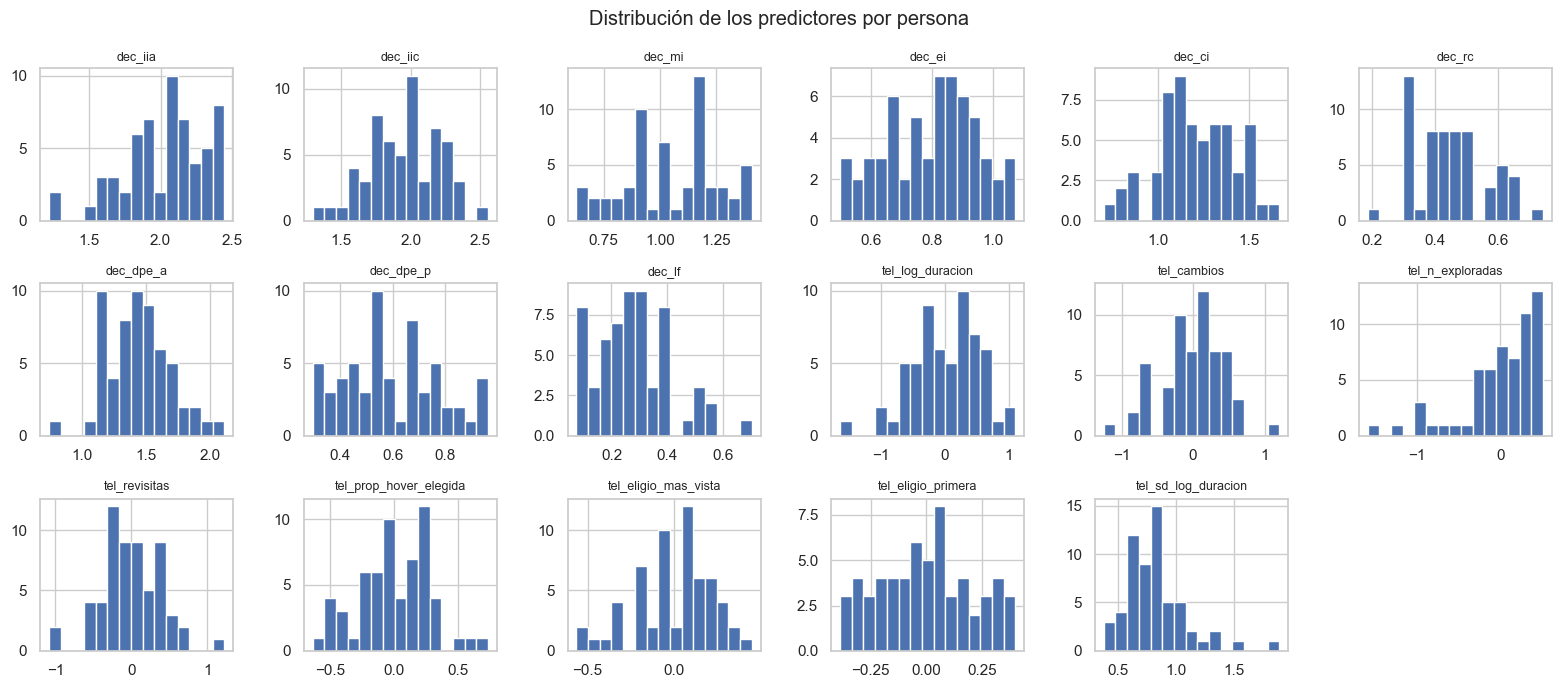

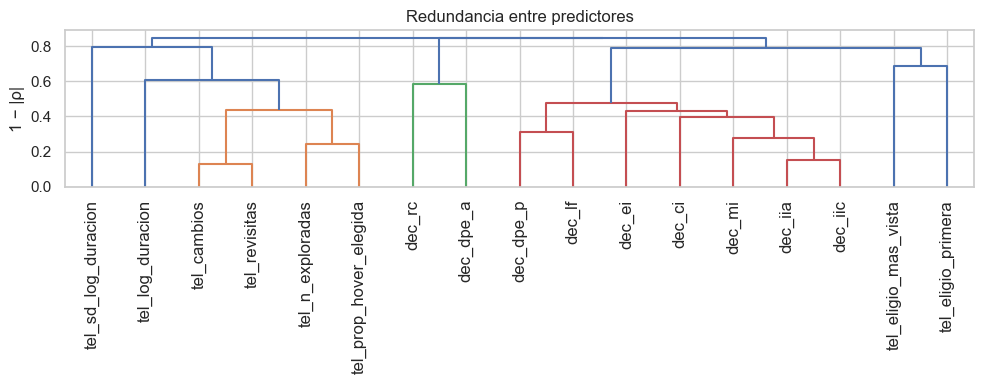

Pares de predictores más redundantes:


,level_0,level_1,rho,abs_rho
182,tel_cambios,tel_revisitas,0.869,0.869
1,dec_iia,dec_iic,0.848,0.848
181,tel_cambios,tel_n_exploradas,0.808,0.808
200,tel_n_exploradas,tel_prop_hover_elegida,-0.759,0.759
19,dec_iic,dec_mi,0.745,0.745
2,dec_iia,dec_mi,0.699,0.699
127,dec_dpe_p,dec_lf,0.686,0.686
8,dec_iia,dec_lf,-0.669,0.669


In [8]:
X_todo = datos[COLS_DEC + COLS_TEL]
fig, axes = plt.subplots(3, 6, figsize=(16, 7))
for ax, c in zip(axes.flat, X_todo.columns):
    ax.hist(X_todo[c], bins=15, color="#4C72B0", edgecolor="white")
    ax.set_title(c, fontsize=9)
for ax in axes.flat[len(X_todo.columns):]:
    ax.axis("off")
plt.suptitle("Distribución de los predictores por persona")
plt.tight_layout(); plt.show()

rho_x = X_todo.corr(method="spearman")
dist = squareform(1 - rho_x.abs().values, checks=False)
fig, ax = plt.subplots(figsize=(10, 4))
hierarchy.dendrogram(hierarchy.linkage(dist, "average"), labels=rho_x.columns, leaf_rotation=90, ax=ax)
ax.set_ylabel("1 − |ρ|"); ax.set_title("Redundancia entre predictores")
plt.tight_layout(); plt.show()

pares = (rho_x.where(np.triu(np.ones(rho_x.shape, bool), k=1)).stack()
         .rename("rho").reset_index().assign(abs_rho=lambda d: d.rho.abs())
         .sort_values("abs_rho", ascending=False))
print("Pares de predictores más redundantes:")
pares.head(8)

## 4. Correlaciones X–Y (Spearman)

Se usa Spearman porque capta relaciones monótonas aunque no sean lineales (clase 3). Hay muchas pruebas (predictores × objetivos), así que se corrige con **FDR de Benjamini-Hochberg** dentro de cada familia de objetivos (compuestos y dimensiones por separado).

Referencia: con n = 60, |ρ| debe superar ≈ 0,25 para ser significativa al 5 % *sin* corregir.

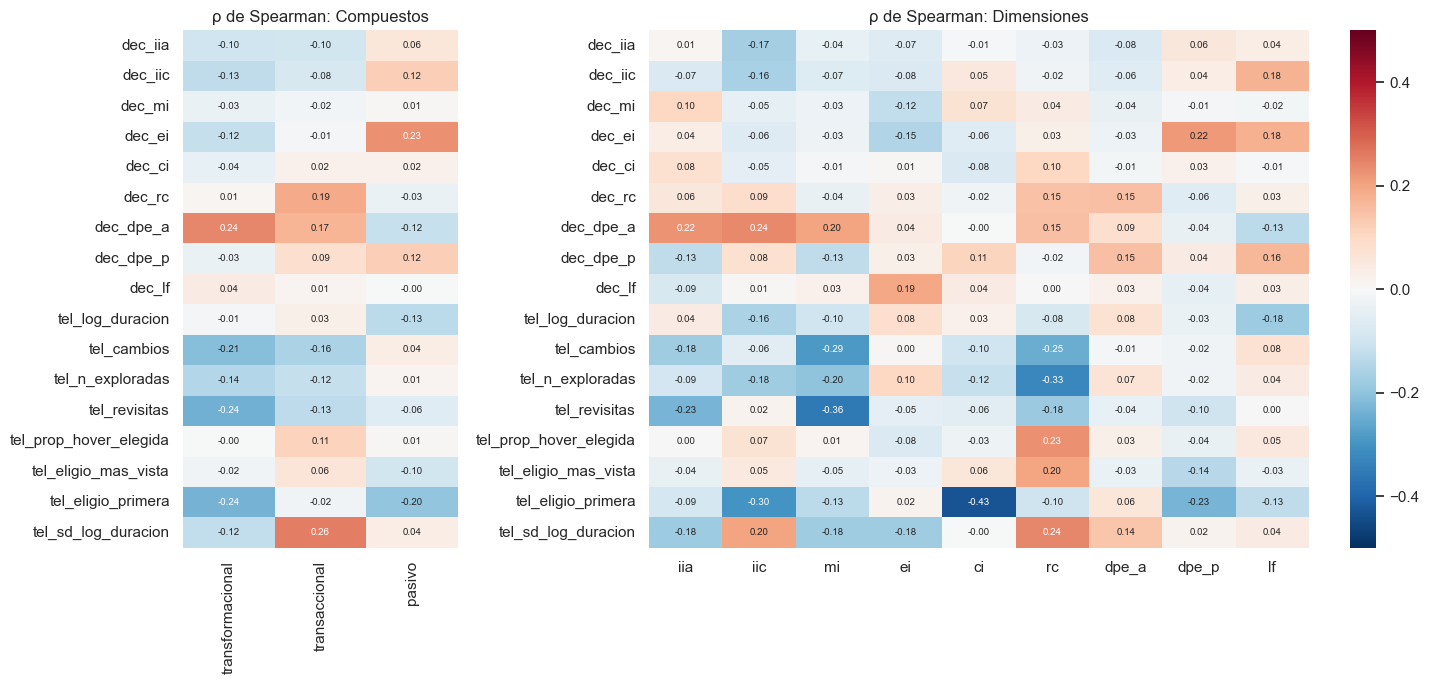

Validez convergente (misma dimensión, simulación vs. MLQ externo):


,objetivo,rho,p,p_fdr
0,iia,0.011,0.934,0.998
18,iic,-0.161,0.220,0.998
36,mi,-0.029,0.824,0.998
54,ei,-0.151,0.248,0.998
72,ci,-0.077,0.561,0.998
90,rc,0.147,0.261,0.998
108,dpe_a,0.086,0.515,0.998
126,dpe_p,0.040,0.763,0.998
144,lf,0.035,0.791,0.998


Correlaciones más fuertes (todas las familias):


,objetivo,predictor,rho,p,p_fdr
83,ci,tel_eligio_primera,-0.433,5.534e-04,0.085
46,mi,tel_revisitas,-0.356,5.294e-03,0.405
96,rc,tel_n_exploradas,-0.328,1.062e-02,0.542
32,iic,tel_eligio_primera,-0.298,2.057e-02,0.787
44,mi,tel_cambios,-0.286,2.674e-02,0.818
33,transaccional,tel_sd_log_duracion,0.257,4.759e-02,0.805
95,rc,tel_cambios,-0.248,5.601e-02,0.998
6,transformacional,dec_dpe_a,0.245,5.940e-02,0.805
101,rc,tel_sd_log_duracion,0.244,6.069e-02,0.998
12,transformacional,tel_revisitas,-0.241,6.372e-02,0.805


In [9]:
def tabla_correlaciones(objetivos):
    filas = []
    for y in objetivos:
        for x in COLS_DEC + COLS_TEL:
            r, p = stats.spearmanr(datos[x], datos[y])
            filas.append({"objetivo": y, "predictor": x, "rho": r, "p": p})
    t = pd.DataFrame(filas)
    t["p_fdr"] = multipletests(t["p"], method="fdr_bh")[1]
    return t

corr_comp = tabla_correlaciones(OBJ_PRINCIPALES)
corr_dims = tabla_correlaciones(DIMS)

fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [3, 9]})
for ax, t, titulo in [(axes[0], corr_comp, "Compuestos"), (axes[1], corr_dims, "Dimensiones")]:
    m = t.pivot(index="predictor", columns="objetivo", values="rho").loc[COLS_DEC + COLS_TEL]
    m = m[[c for c in OBJETIVOS if c in m.columns]]
    sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-0.5, vmax=0.5, ax=ax,
                cbar=ax is axes[1], annot_kws={"size": 7})
    ax.set_title(f"ρ de Spearman: {titulo}"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

# Diagonal: ¿la dimensión de la simulación correlaciona con la misma dimensión del MLQ?
diag = corr_dims[corr_dims.predictor == "dec_" + corr_dims.objetivo][["objetivo", "rho", "p", "p_fdr"]]
print("Validez convergente (misma dimensión, simulación vs. MLQ externo):")
display(diag)

print("Correlaciones más fuertes (todas las familias):")
pd.concat([corr_comp, corr_dims]).sort_values("p").head(10)

**Intervalos de confianza por bootstrap** para las correlaciones más fuertes. Con 60 personas los intervalos son anchos, y un intervalo que cruza 0 indica que no se puede descartar ausencia de relación.

In [10]:
rng = np.random.default_rng(SEED)
def ic_bootstrap(x, y, B=2000):
    n = len(x); idx = rng.integers(0, n, size=(B, n))
    rs = [stats.spearmanr(x[i], y[i])[0] for i in idx]
    return np.nanpercentile(rs, [2.5, 97.5])

top = pd.concat([corr_comp, corr_dims]).sort_values("p").head(10).copy()
ics = [ic_bootstrap(datos[r.predictor].values, datos[r.objetivo].values) for r in top.itertuples()]
top["ic95_inf"], top["ic95_sup"] = zip(*ics)
top[["objetivo", "predictor", "rho", "ic95_inf", "ic95_sup", "p", "p_fdr"]]

,objetivo,predictor,rho,ic95_inf,ic95_sup,p,p_fdr
83,ci,tel_eligio_primera,-0.433,-0.621,-0.194,5.534e-04,0.085
46,mi,tel_revisitas,-0.356,-0.566,-0.122,5.294e-03,0.405
96,rc,tel_n_exploradas,-0.328,-0.553,-0.074,1.062e-02,0.542
32,iic,tel_eligio_primera,-0.298,-0.492,-0.067,2.057e-02,0.787
44,mi,tel_cambios,-0.286,-0.516,-0.035,2.674e-02,0.818
33,transaccional,tel_sd_log_duracion,0.257,0.009,0.452,4.759e-02,0.805
95,rc,tel_cambios,-0.248,-0.487,0.011,5.601e-02,0.998
6,transformacional,dec_dpe_a,0.245,-0.035,0.490,5.940e-02,0.805
101,rc,tel_sd_log_duracion,0.244,0.015,0.468,6.069e-02,0.998
12,transformacional,tel_revisitas,-0.241,-0.482,0.011,6.372e-02,0.805


## 5. Modelos predictivos (clase 2)

**Benchmark:** predecir siempre el promedio de entrenamiento (`DummyRegressor`). Un modelo solo aporta si su **R² fuera de muestra es mayor que 0** y supera al benchmark.

**Modelos:**
- **Ridge** (L2) y **Lasso** (L1): adecuados para n pequeño y predictores correlacionados. λ (`alpha`) se elige con validación cruzada *interna*.
- **Random Forest** con hojas grandes (`min_samples_leaf=5`): un modelo no lineal de comparación.

**Validación cruzada anidada:**
- Ciclo externo: K-fold con K = 5, repetido 10 veces con particiones distintas (5 veces para Random Forest, que es más lento).
- En cada repetición se juntan las 60 predicciones fuera de muestra y se calculan R², MAE y RMSE.
- `StandardScaler` y la búsqueda de λ están dentro del `Pipeline`, así que se ajustan solo con los datos de entrenamiento de cada fold (sin fuga de información).

**Comparación clave:** A (solo decisiones), B (solo telemetría) y A+B. Si A+B no mejora a A, la telemetría no agrega información.

In [11]:
ALPHAS = np.logspace(-2, 4, 40)
def modelos():
    return {
        "Benchmark (media)": DummyRegressor(strategy="mean"),
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=ALPHAS)),
        "Lasso": make_pipeline(StandardScaler(), LassoCV(cv=5, alphas=np.logspace(-3, 1, 40), max_iter=20000, random_state=SEED)),
        "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.5,
                                               random_state=SEED),
    }

N_REP = 10
N_REP_RF = 5  # el bosque es ~30 veces más lento que Ridge; 5 repeticiones bastan como comparación
def evaluar(modelo, X, y, n_rep=N_REP):
    r2, mae, rmse = [], [], []
    for rep in range(n_rep):
        cv = KFold(n_splits=5, shuffle=True, random_state=rep)
        pred = cross_val_predict(modelo, X, y, cv=cv)
        r2.append(r2_score(y, pred)); mae.append(mean_absolute_error(y, pred))
        rmse.append(np.sqrt(mean_squared_error(y, pred)))
    return {"R2": np.mean(r2), "R2_sd": np.std(r2), "MAE": np.mean(mae), "RMSE": np.mean(rmse)}

resultados = []
for y_col in OBJETIVOS:
    y = datos[y_col].values
    for conj, cols in CONJUNTOS.items():
        for nombre, mod in modelos().items():
            if nombre.startswith("Benchmark") and conj != "A: decisiones":
                continue  # el benchmark no depende de X
            res = evaluar(mod, datos[cols].values, y, n_rep=N_REP_RF if nombre == "Random Forest" else N_REP)
            resultados.append({"objetivo": y_col, "conjunto": "—" if nombre.startswith("Benchmark") else conj,
                               "modelo": nombre, **res})
res = pd.DataFrame(resultados)
res[res.objetivo.isin(OBJ_PRINCIPALES)].sort_values(["objetivo", "R2"], ascending=[True, False])

,objetivo,conjunto,modelo,R2,R2_sd,MAE,RMSE
20,pasivo,—,Benchmark (media),-0.038,0.019,1.426,1.768
24,pasivo,B: telemetría,Ridge,-0.050,0.026,1.433,1.779
27,pasivo,A+B,Ridge,-0.058,0.031,1.434,1.785
22,pasivo,A: decisiones,Lasso,-0.069,0.029,1.438,1.794
21,pasivo,A: decisiones,Ridge,-0.072,0.033,1.439,1.797
28,pasivo,A+B,Lasso,-0.078,0.051,1.443,1.801
25,pasivo,B: telemetría,Lasso,-0.078,0.037,1.453,1.802
26,pasivo,B: telemetría,Random Forest,-0.108,0.034,1.455,1.827
29,pasivo,A+B,Random Forest,-0.138,0.053,1.454,1.851
23,pasivo,A: decisiones,Random Forest,-0.159,0.055,1.482,1.868


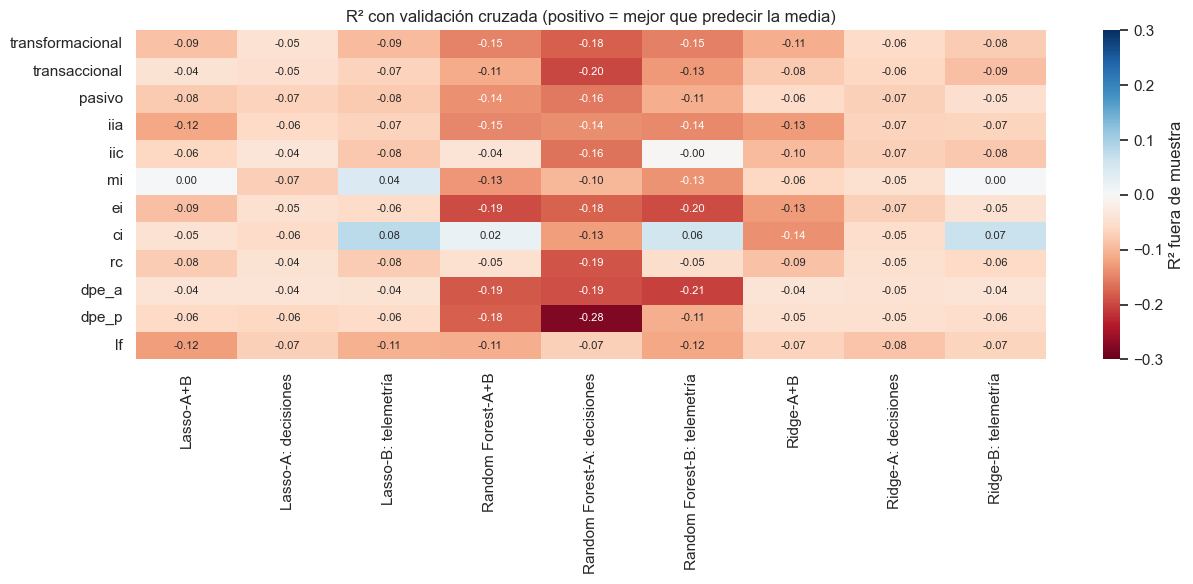

Mejor modelo por objetivo:


,modelo,conjunto,R2,R2_sd,MAE
objetivo,,,,,
transformacional,Lasso,A: decisiones,-0.045,0.045,1.150
transaccional,Lasso,A+B,-0.045,0.023,1.221
pasivo,Ridge,B: telemetría,-0.050,0.026,1.433
iia,Lasso,A: decisiones,-0.059,0.056,1.739
iic,Random Forest,B: telemetría,-0.002,0.031,1.341
mi,Lasso,B: telemetría,0.043,0.039,1.926
ei,Ridge,B: telemetría,-0.046,0.030,1.518
ci,Lasso,B: telemetría,0.081,0.041,1.286
rc,Lasso,A: decisiones,-0.043,0.029,1.448


In [12]:
tabla_r2 = (res[~res.modelo.str.startswith("Benchmark")]
            .pivot_table(index="objetivo", columns=["modelo", "conjunto"], values="R2")
            .loc[OBJETIVOS])
fig, ax = plt.subplots(figsize=(13, 6))
sns.heatmap(tabla_r2, annot=True, fmt=".2f", cmap="RdBu", center=0, vmin=-0.3, vmax=0.3, ax=ax,
            annot_kws={"size": 8}, cbar_kws={"label": "R² fuera de muestra"})
ax.set_title("R² con validación cruzada (positivo = mejor que predecir la media)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

mejor = (res[~res.modelo.str.startswith("Benchmark")].sort_values("R2", ascending=False)
         .groupby("objetivo").head(1).set_index("objetivo").loc[OBJETIVOS])
print("Mejor modelo por objetivo:")
mejor[["modelo", "conjunto", "R2", "R2_sd", "MAE"]]

## 6. Prueba de permutación: ¿el mejor R² supera al azar?

Con 12 objetivos, 3 conjuntos y 3 modelos, alguna combinación puede salir positiva solo por suerte. La prueba de permutación revuelve Y, rompiendo cualquier relación real con X, y repite exactamente el mismo procedimiento. El **p-valor** es la fracción de permutaciones con un R² igual o mayor al observado.

Se aplica a Ridge con A+B y al mejor modelo de cada compuesto, y también a toda dimensión cuyo mejor modelo haya dado R² > 0. Esas son justo las combinaciones que más podrían ser falsos positivos.

In [13]:
def r2_cv(modelo, X, y, seed=0):
    pred = cross_val_predict(modelo, X, y, cv=KFold(5, shuffle=True, random_state=seed))
    return r2_score(y, pred)

N_PERM = 300
rng = np.random.default_rng(SEED)
filas_perm, nulos = [], {}
obj_perm = OBJ_PRINCIPALES + [o for o in DIMS if mejor.loc[o, "R2"] > 0]
for y_col in obj_perm:
    candidatos = {("Ridge", "A+B")} if y_col in OBJ_PRINCIPALES else set()
    candidatos.add((mejor.loc[y_col, "modelo"], mejor.loc[y_col, "conjunto"]))
    for nombre, conj in sorted(candidatos):
        X = datos[CONJUNTOS[conj]].values; y = datos[y_col].values
        obs = r2_cv(modelos()[nombre], X, y)
        n_perm = N_PERM if nombre != "Random Forest" else 100
        nulo = np.array([r2_cv(modelos()[nombre], X, rng.permutation(y)) for _ in range(n_perm)])
        nulos[(y_col, nombre, conj)] = (obs, nulo)
        filas_perm.append({"objetivo": y_col, "modelo": nombre, "conjunto": conj, "R2_obs": obs,
                           "R2_nulo_p95": np.percentile(nulo, 95),
                           "p_perm": (np.sum(nulo >= obs) + 1) / (len(nulo) + 1)})
perm = pd.DataFrame(filas_perm)
perm

,objetivo,modelo,conjunto,R2_obs,R2_nulo_p95,p_perm
0,transformacional,Lasso,A: decisiones,-0.032,-0.007,0.299
1,transformacional,Ridge,A+B,-0.143,-0.008,0.890
2,transaccional,Lasso,A+B,-0.037,-0.005,0.312
3,transaccional,Ridge,A+B,-0.052,-0.007,0.478
4,pasivo,Ridge,A+B,-0.041,-0.006,0.389
5,pasivo,Ridge,B: telemetría,-0.016,-0.007,0.106
6,mi,Lasso,B: telemetría,0.037,-0.006,0.030
7,ci,Lasso,B: telemetría,0.111,-0.002,0.003


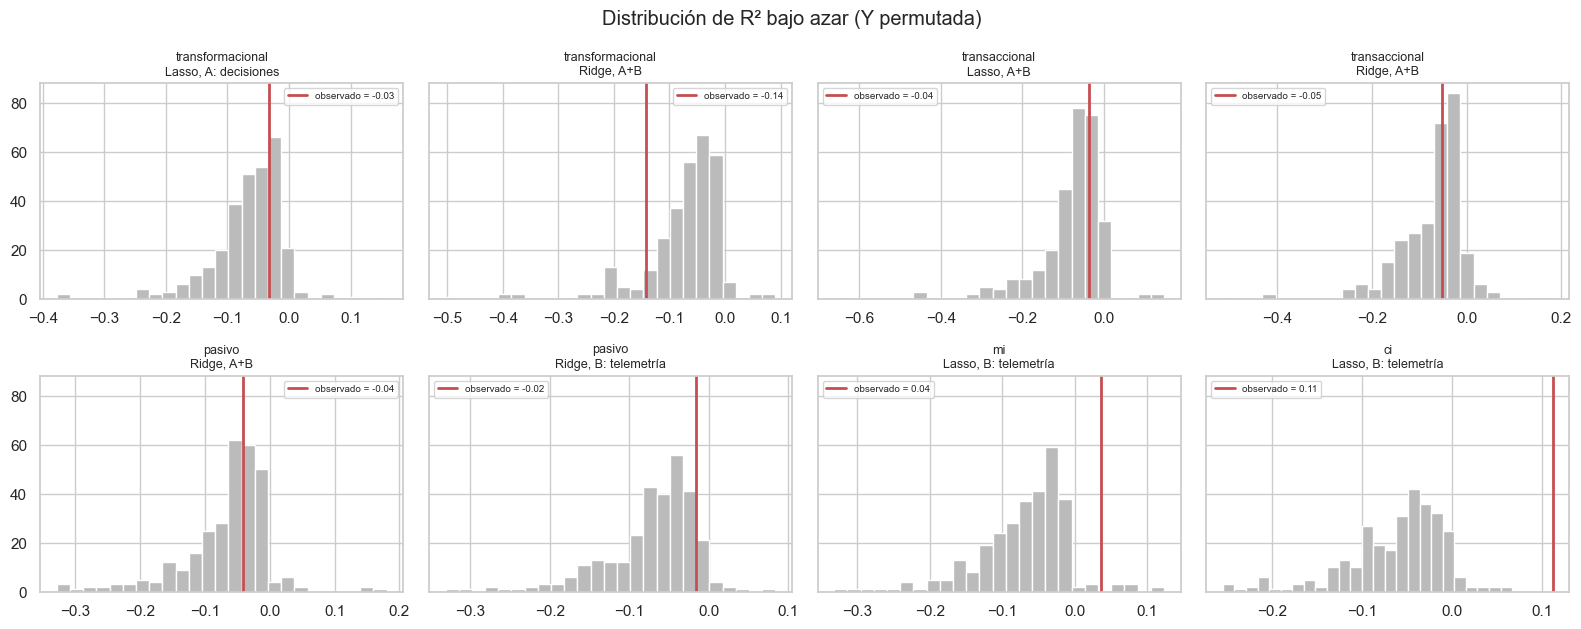

In [14]:
n_cols = 4; n_filas = int(np.ceil(len(nulos) / n_cols))
fig, axes = plt.subplots(n_filas, n_cols, figsize=(16, 3.2 * n_filas), sharey=True, squeeze=False)
for ax in axes.flat[len(nulos):]:
    ax.axis("off")
for ax, ((y_col, nombre, conj), (obs, nulo)) in zip(axes.flat, nulos.items()):
    ax.hist(nulo, bins=25, color="#BBBBBB")
    ax.axvline(obs, color="#C44E52", lw=2, label=f"observado = {obs:.2f}")
    ax.set_title(f"{y_col}\n{nombre}, {conj}", fontsize=9); ax.legend(fontsize=7)
plt.suptitle("Distribución de R² bajo azar (Y permutada)")
plt.tight_layout(); plt.show()

## 7. Importancia de variables (clase 3)

**Importancia por permutación** calculada *en los datos de validación* de cada fold (5 folds × 10 repeticiones): cuánto empeora el R² al revolver una columna. Se aplica al **mejor modelo del objetivo con mayor R²**. Para los modelos lineales también se reporta en qué fracción de los folds el coeficiente mantuvo su signo (`signo_estable`), como medida de estabilidad.

⚠️ Si el modelo no supera al benchmark (R² ≤ 0), estas importancias **no se deben interpretar**: explicarían un modelo que no predice. Se muestran para completar el flujo.

Objetivo: ci | modelo: Lasso, B: telemetría | R² = 0.081


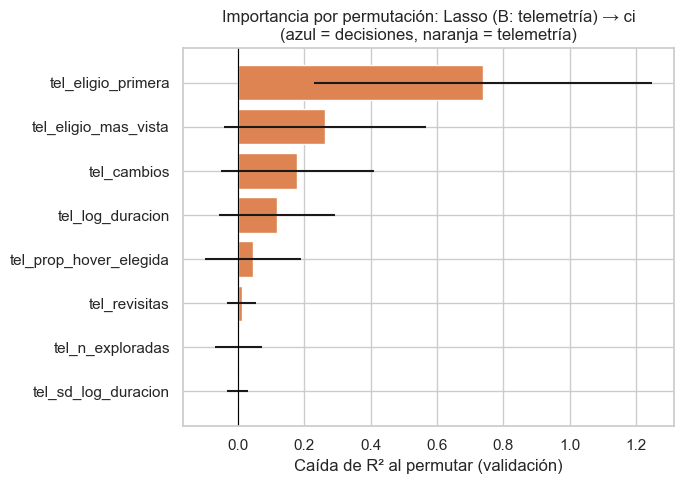

,importancia_media,importancia_sd,coef_std_medio,signo_estable
tel_eligio_primera,7.381e-01,0.508,-0.878,1.00
tel_eligio_mas_vista,2.621e-01,0.303,0.543,0.98
tel_cambios,1.798e-01,0.231,-0.443,0.94
tel_log_duracion,1.176e-01,0.175,0.420,0.98
tel_prop_hover_elegida,4.730e-02,0.145,-0.172,0.66
tel_revisitas,1.192e-02,0.044,-0.003,0.20
tel_n_exploradas,1.767e-03,0.071,-0.060,0.26
tel_sd_log_duracion,-8.995e-05,0.031,0.110,0.80


In [15]:
obj_imp = mejor["R2"].idxmax()
mod_imp, conj_imp = mejor.loc[obj_imp, "modelo"], mejor.loc[obj_imp, "conjunto"]
cols = CONJUNTOS[conj_imp]
X = datos[cols].values; y = datos[obj_imp].values
imps, coefs = [], []
for rep in range(10):
    for tr, te in KFold(5, shuffle=True, random_state=rep).split(X):
        m = modelos()[mod_imp].fit(X[tr], y[tr])
        pi = permutation_importance(m, X[te], y[te], scoring="r2", n_repeats=10, random_state=rep)
        imps.append(pi.importances_mean)
        es_lineal = hasattr(m, "steps") and hasattr(m[-1], "coef_")
        coefs.append(m[-1].coef_ if es_lineal else np.full(len(cols), np.nan))
imp = pd.DataFrame({"importancia_media": np.mean(imps, 0), "importancia_sd": np.std(imps, 0),
                    "coef_std_medio": np.mean(coefs, 0),
                    "signo_estable": (np.sign(coefs) == np.sign(np.mean(coefs, 0))).mean(0)},
                   index=cols).sort_values("importancia_media", ascending=False)
print(f"Objetivo: {obj_imp} | modelo: {mod_imp}, {conj_imp} | R² = {mejor.loc[obj_imp, 'R2']:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
imp_plot = imp.iloc[::-1]
ax.barh(imp_plot.index, imp_plot.importancia_media, xerr=imp_plot.importancia_sd,
        color=["#4C72B0" if c.startswith("dec_") else "#DD8452" for c in imp_plot.index])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Caída de R² al permutar (validación)")
ax.set_title(f"Importancia por permutación: {mod_imp} ({conj_imp}) → {obj_imp}\n(azul = decisiones, naranja = telemetría)")
plt.tight_layout(); plt.show()
imp

## 8. Resumen automático

In [16]:
bench = res[res.modelo.str.startswith("Benchmark")].set_index("objetivo")["R2"]
resumen = pd.DataFrame({
    "R2_benchmark": bench.loc[OBJETIVOS],
    "mejor_R2": mejor["R2"],
    "mejor_modelo": mejor["modelo"] + " | " + mejor["conjunto"],
    "R2_Ridge_A": res.query("modelo=='Ridge' and conjunto=='A: decisiones'").set_index("objetivo")["R2"],
    "R2_Ridge_B": res.query("modelo=='Ridge' and conjunto=='B: telemetría'").set_index("objetivo")["R2"],
    "R2_Ridge_AB": res.query("modelo=='Ridge' and conjunto=='A+B'").set_index("objetivo")["R2"],
})
n_sig_comp = (corr_comp.p_fdr < 0.05).sum(); n_sig_dims = (corr_dims.p_fdr < 0.05).sum()
print(f"Correlaciones significativas tras FDR: {n_sig_comp} (compuestos), {n_sig_dims} (dimensiones)")
print(f"Objetivos con R² fuera de muestra > 0: {(resumen.mejor_R2 > 0).sum()} de {len(resumen)}")
print(f"Permutaciones con p < 0,05: {(perm.p_perm < 0.05).sum()} de {len(perm)}")
resumen

Correlaciones significativas tras FDR: 0 (compuestos), 0 (dimensiones)
Objetivos con R² fuera de muestra > 0: 2 de 12
Permutaciones con p < 0,05: 2 de 8


,R2_benchmark,mejor_R2,mejor_modelo,R2_Ridge_A,R2_Ridge_B,R2_Ridge_AB
objetivo,,,,,,
transformacional,-0.034,-0.045,Lasso | A: decisiones,-0.058,-0.076,-0.110
transaccional,-0.040,-0.045,Lasso | A+B,-0.063,-0.090,-0.080
pasivo,-0.038,-0.050,Ridge | B: telemetría,-0.072,-0.050,-0.058
iia,-0.036,-0.059,Lasso | A: decisiones,-0.069,-0.067,-0.128
iic,-0.033,-0.002,Random Forest | B: telemetría,-0.071,-0.081,-0.096
mi,-0.029,0.043,Lasso | B: telemetría,-0.048,0.004,-0.062
ei,-0.032,-0.046,Ridge | B: telemetría,-0.071,-0.046,-0.129
ci,-0.051,0.081,Lasso | B: telemetría,-0.055,0.066,-0.137
rc,-0.036,-0.043,Lasso | A: decisiones,-0.049,-0.060,-0.087


## 9. Conclusiones (resultados de la ejecución del 26-11-2026, semilla 42)

**1. Las decisiones explícitas no se relacionan con el MLQ externo.**
- Ninguna dimensión de la simulación correlaciona con la misma dimensión del MLQ externo: todas las |ρ| son ≤ 0,16 y ninguna es significativa.
- Los modelos que usan solo decisiones (conjunto A) no superan al benchmark para ningún objetivo.
- Hay dos lecturas posibles:
  - las etiquetas expertas de las alternativas no miden lo mismo que el cuestionario, o
  - el autorreporte y la conducta en la simulación capturan aspectos distintos del liderazgo. Esta es justamente la motivación del proyecto.

**2. Los compuestos tampoco se predicen.**
- Para `transformacional`, `transaccional` y `pasivo`, ningún modelo supera al benchmark.
- Ninguna prueba de permutación es significativa: los p-valores van de 0,11 a 0,89.
- El compuesto transaccional además tiene baja consistencia interna (α = 0,30).

**3. Hay una señal en la telemetría para la Consideración individualizada (`ci`).**
- Lasso solo con telemetría logra R² ≈ 0,08 fuera de muestra (prueba de permutación: p = 0,003).
- Las variables más importantes forman un patrón de **deliberación**. Puntúan más alto en `ci` quienes:
  - menos veces eligen la primera alternativa que miran (ρ = −0,43; IC95 % de −0,62 a −0,19);
  - más veces eligen la que más revisaron;
  - cambian menos entre opciones;
  - se toman más tiempo.
- `mi` (motivación inspiradora) muestra una señal similar, pero más débil: R² ≈ 0,04, p = 0,03.

**4. Cautelas antes de reportarlo.**
- **Selección del mejor resultado.** `ci` se eligió como el mejor de 12 objetivos y varios modelos. La prueba de permutación no corrige por esa selección. Con Bonferroni sobre las 8 pruebas, `ci` sigue siendo significativa (0,003 × 8 ≈ 0,02), pero `mi` no lo es.
- **Correlaciones con FDR.** Tras la corrección, la correlación más fuerte (`ci` ~ `tel_eligio_primera`) queda en el límite: p_FDR = 0,085.
- **Tamaño del efecto.** R² ≈ 0,08 es un efecto pequeño y la muestra es de 60 personas. Debe presentarse como **hipótesis exploratoria** que conviene confirmar con nuevos participantes, no como un hallazgo confirmado.

**5. Lectura para el proyecto.**
- El resultado favorece la línea de **datos de proceso**: la telemetría aporta información sobre el autorreporte que las elecciones no aportan.
- La señal es específica de una dimensión y su tamaño es modesto.